**Agenda**
- **PART 1 — Why Pruning is Needed**
- **PART 2 — Pre-Pruning Techniques**
- **PART 3 — Post-Pruning Techniques**
- **PART 4 — Hyperparameters & Tuning**
- **PART 5 — Customer Churn Case Study**
- **PART 6 — Model Interpretation**
- **PART 7 — Advanced Techniques**

# **PART 1 — Why Pruning is Needed**

**The Core Problem of Decision Trees**

- Decision Trees have almost unlimited flexibility.

**Given enough splits:**

- Training Accuracy → 100%
- Training Error → 0

**But:**

- Perfect training performance ≠ Good model


**Example**
Suppose we have:
| Age | Churn |
| --- | ----- |
| 20  | Yes   |
| 21  | Yes   |
| 22  | No    |
| 23  | Yes   |
| 24  | No    |



**A deep tree may create:**

- Age <= 20.5
- Age <= 21.5
- Age <= 22.5
- Age <= 23.5
...

Memorizing individual records.

**Visualization**


In [ ]:
print("""
Shallow Tree

      Root
     /    \\
  Leaf   Leaf

Low Variance
High Bias
""")


Shallow Tree

      Root
     /    \
  Leaf   Leaf

Low Variance
High Bias



In [ ]:
print("""
Very Deep Tree

Root
 |
 |
 |
 |
 |
 |
Leaves

Low Bias
Very High Variance
""")


Very Deep Tree

Root
 |
 |
 |
 |
 |
 |
Leaves

Low Bias
Very High Variance



**Bias-Variance Perspective**

- Decision Trees naturally have:

  - Low Bias

**High Variance**

- Pruning reduces:

  - Variance

- at the cost of slightly increasing:

  - Bias

**Interview One-Liner**

- Pruning controls variance in decision trees and improves generalization.


**Why Deep Trees Fail**

- Deep trees:

  - Learn noise
  - Learn outliers
  - Learn accidental patterns

**Instead of:**

- Signal

  - they learn:

     - Signal + Noise

**Example**

- Customer churn dataset:

  - A deep tree learns:

- Customer ID = 45871
- → Churn

This is meaningless.

IDs contain no predictive information.

Top - down approach - Pre Prunning approach
    --> Instead of builiind a complete useles s tree in the begining itself lets cut it short
    --> max depth ( if max depth is too deep  --> overfitting
            --> if max depth / tree is too shallow --> underfitting
    --> min samples split
    --> min sample leaf


bottom - up approach = Post pruning approach
    --> build a complete tree with all possible combinations and then see which branches to prune
    --> ccp_alpha

# **PART 2 — Pre-Pruning Techniques**

## 🌳 What is Pre-Pruning?

**Pre-Pruning** means **stopping the growth of a decision tree before it becomes too complex and overfits the training data.**

### `max_depth`

- One of the **most important pre-pruning parameters**.
- Controls the **maximum depth (number of levels)** the tree can grow.

**Example:**

```python
DecisionTreeClassifier(max_depth=3)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

DecisionTreeClassifier(
    max_depth=4
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [ ]:
print("""
max_depth = 2

        Root
       /    \\
      A      B
     / \\    / \\
""")


max_depth = 2

        Root
       /    \
      A      B
     / \    / \



In [ ]:
print("""
max_depth = 20

Huge Tree
Many Leaves
High Variance
""")


max_depth = 20

Huge Tree
Many Leaves
High Variance



## min_samples_split

- Minimum samples needed to split a node.

**Example**

In [ ]:
DecisionTreeClassifier(
    min_samples_split=20
)

,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",20
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

**Meaning:**

- Node must contain at least:

  - 20 samples

before splitting.

**Benefit**

- Prevents:

  - Tiny meaningless splits.


## min_samples_leaf

- Minimum samples required in leaf node.

**Example**


In [ ]:
DecisionTreeClassifier(
    min_samples_leaf=10
)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

**Without restriction:**

- Leaf A = 1 sample
- Leaf B = 2 samples

Very unstable.

**With restriction:**

- Leaf A = 10+
- Leaf B = 10+

More reliable.


## max_leaf_nodes

- Maximum number of leaves allowed.

**Example**


In [ ]:
DecisionTreeClassifier(
    max_leaf_nodes=25
)

,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",25
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

**Controls:**

- Overall tree complexity.


## min_impurity_decrease

- Node only splits if impurity reduction exceeds threshold.

**Example**

In [ ]:
DecisionTreeClassifier(
    min_impurity_decrease=0.01
)

,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.01
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :te

**Benefit:**

- Prevents tiny useless splits.

**Pre-Pruning Summary**
| Parameter             | Controls          |
| --------------------- | ----------------- |
| max_depth             | Tree depth        |
| min_samples_split     | Split eligibility |
| min_samples_leaf      | Leaf size         |
| max_leaf_nodes        | Tree complexity   |
| min_impurity_decrease | Split quality     |


# **PART 3 — Post-Pruning Techniques**

## 🌳 Why Post-Pruning?

Instead of restricting tree growth:

- Allow the tree to **fully grow**.
- Then **remove unnecessary branches**.

### Philosophy

**Grow First → Prune Later**

---

## ✂️ Cost Complexity Pruning (CART)

Cost Complexity Pruning is the main post-pruning technique used by **CART** and **Scikit-Learn**.

### Objective

$$
R(T) + \alpha |T|
$$

Where:

- $R(T)$ = Training Error
- $|T|$ = Number of Leaves
- $\alpha$ = Complexity Penalty

### Interpretation

| Tree | Error | Complexity |
|---|---|---|
| Large Tree | Low | High |
| Small Tree | Higher | Low |

**Pruning seeks a balance between accuracy and tree complexity.**

---

## 🎯 `ccp_alpha` Hyperparameter

`ccp_alpha` controls **how aggressively the tree is pruned**.

```python
DecisionTreeClassifier(ccp_alpha=0.01)

## ✂️ What does `ccp_alpha` do?

`ccp_alpha` is the **complexity penalty** used in Cost Complexity Pruning.

The objective is:

$$
R(T) + \alpha |T|
$$

Where:

- $R(T)$ = Error of the tree
- $|T|$ = Number of leaves
- $\alpha$ = `ccp_alpha`

### 🔍 How does it work?

`ccp_alpha` puts a **"cost" on tree complexity**.

The algorithm asks:

> **"Is the reduction in error worth keeping this additional branch?"**

- If **yes** → Keep the branch
- If **no** → Prune the branch

### 📈 Effect of `ccp_alpha`

| `ccp_alpha` | Pruning | Tree |
|---|---|---|
| `0` | No pruning | Large/complex |
| Small | Light pruning | Moderately complex |
| Large | Aggressive pruning | Small/simple |
| Too large | Excessive pruning | Underfitting |

### 🎯 Why tune `ccp_alpha`?

We try different values using **Cross-Validation** and select the value that gives the best **generalization performance**.

```python
DecisionTreeClassifier(ccp_alpha=0.01)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

DecisionTreeClassifier(
    ccp_alpha=0.01)

,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",0.01
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If 

# ✂️ Cost Complexity Pruning — How Does It Work?

Cost Complexity Pruning tries to find a balance between:

- **Low training error**
- **Low tree complexity**

### Cost Complexity Formula

$$
\boxed{\text{Cost}(T) = R(T) + \alpha |T|}
$$

Where:

- $R(T)$ → Total impurity/error of the tree
- $|T|$ → Number of leaves
- $\alpha$ → Complexity penalty (`ccp_alpha`)

---

## 1. Start with a Fully Grown Tree

Suppose we have the following **subtree**:
            (Root Node)
             B
           /   \
          D     E

Here:

* `B` is an internal node
* `D` and `E` are leaves
* Number of leaves = **2**

The algorithm asks:

> **Should we keep this subtree, or replace it with a single leaf?**

---

## 2. Calculate the Error Before Pruning

Suppose the impurity/error of the two leaves is:

$$
R(T_t) = 0.10
$$

So, if we **keep the subtree**:

             B
           /   \
          D     E

Leaves = 2
Error  = 0.10

---

## 3. Calculate the Error After Pruning

If we prune the subtree, we replace the entire subtree with one leaf:

```text
             B
             |
           Leaf

Leaves = 1
Error  = 0.14
```

The error increases because we have removed a useful split:

$$
R(T_t^{leaf}) = 0.14
$$

---

## 4. Calculate the Effective `ccp_alpha`

The effective alpha for this subtree is:

$$
\alpha_{effective}
=
\frac{
R(T_t^{leaf}) - R(T_t)
}{
|T_t| - 1
}
$$

Substituting our values:

$$
\alpha_{effective}
=
\frac{0.14 - 0.10}{2-1}
$$

$$
\boxed{\alpha_{effective}=0.04}
$$

### What does `0.04` mean?

It means that when:

$$
ccp\_alpha = 0.04
$$

the algorithm is **indifferent between keeping and pruning this subtree**.

This is the point at which pruning this subtree becomes worthwhile.

---

# 5. Why Do We Divide by `(|T_t| - 1)`?

Before pruning:

$$
|T_t| = 2
$$

After pruning:

$$
1 \text{ leaf}
$$

Therefore, the reduction in complexity is:

$$
2-1=1
$$

So the effective alpha represents:

$$
\boxed{
\frac{\text{Increase in error}}
{\text{Reduction in number of leaves}}
}
$$

In our example:

$$
\frac{0.14-0.10}{2-1}
=
0.04
$$

So we are accepting an error increase of **0.04** to remove **one leaf of complexity**.

---

# 6. What Happens to the Whole Tree?

A decision tree has many internal nodes/subtrees.

The algorithm calculates an effective alpha for each possible subtree.

For example:

| Subtree   | Effective Alpha |
| --------- | --------------: |
| Subtree A |            0.01 |
| Subtree B |            0.03 |
| Subtree C |            0.02 |
| Subtree D |            0.05 |

The algorithm starts with the subtree having the **smallest effective alpha**.

```text
Smallest alpha
      ↓
Prune that subtree
      ↓
Tree becomes smaller
      ↓
Recalculate effective alphas
      ↓
Prune next subtree
      ↓
Repeat...
```

Therefore, pruning happens **step-by-step**.

---

# 7. What Does `cost_complexity_pruning_path()` Do?

When we run:

```python
path = tree.cost_complexity_pruning_path(
    X_train,
    y_train
)
```

Scikit-learn calculates the sequence of pruning steps for the tree.

Conceptually:

```text
Fully grown tree
       ↓
Calculate effective alphas
       ↓
Find smallest alpha
       ↓
Prune corresponding subtree
       ↓
Recalculate
       ↓
Find next smallest alpha
       ↓
Prune again
       ↓
Continue until the tree becomes a single root leaf
```

---

# 8. `path.ccp_alphas`

We can access the calculated alpha values using:

```python
alphas = path.ccp_alphas
```

For example:

```text
[0.0000,
 0.0012,
 0.0025,
 0.0041,
 0.0078,
 0.0150]
```

These are the **candidate pruning values** generated from the tree.

Each value represents a point where the tree can move to a simpler structure.

---

# 9. `path.impurities`

We can also access:

```python
path.impurities
```

These represent the total leaf impurity of the tree at each pruning stage.

Conceptually:

| `ccp_alpha` | Number of Leaves | Impurity |
| ----------: | ---------------: | -------: |
|      0.0000 |               50 |     0.10 |
|      0.0012 |               45 |     0.11 |
|      0.0025 |               38 |     0.12 |
|      0.0041 |               30 |     0.14 |
|      0.0078 |               20 |     0.18 |
|      0.0150 |               10 |     0.25 |

As `ccp_alpha` increases:

$$
\text{More pruning}
\rightarrow
\text{Fewer leaves}
\rightarrow
\text{Higher training impurity}
$$

---

# 10. What Does `ccp_alpha` Actually Control?

`ccp_alpha` controls how much we **penalize complexity**.

### Small `ccp_alpha`

```text
Small penalty
     ↓
Branches are worth keeping
     ↓
Less pruning
     ↓
Larger tree
```

### Large `ccp_alpha`

```text
Large penalty
     ↓
Branches need to provide more benefit
     ↓
More pruning
     ↓
Smaller tree
```

---

# 11. What Happens When `ccp_alpha = 0`?

If:

```python
ccp_alpha = 0
```

then:

$$
R(T) + 0|T| = R(T)
$$

There is no complexity penalty.

Therefore, the algorithm focuses only on minimizing training impurity.

```text
ccp_alpha = 0
      ↓
No complexity penalty
      ↓
No cost-complexity pruning
      ↓
Fully grown / larger tree
```

---

# 12. How Does `GridSearchCV` Fit Into This?

`cost_complexity_pruning_path()` gives us candidate values:

```text
cost_complexity_pruning_path()
            ↓
Candidate alphas
            ↓
[0, .0012, .0025, .0041, ...]
```

Then `GridSearchCV` tests these values using cross-validation:

```text
             Candidate alphas
                    ↓
        ┌───────────┼───────────┐
        ↓           ↓           ↓
      0.0012      0.0025      0.0041
        ↓           ↓           ↓
       CV          CV          CV
        ↓           ↓           ↓
      Score       Score       Score
        └───────────┼───────────┘
                    ↓
              Best alpha
```

So:

### `cost_complexity_pruning_path()`

> Finds **candidate pruning points**.

### `GridSearchCV`

> Finds which candidate gives the **best validation performance**.

---

# ⭐ Complete Workflow

```text
Fully Grown Decision Tree
          ↓
cost_complexity_pruning_path()
          ↓
Calculate effective alpha
for different subtrees
          ↓
Generate candidate ccp_alpha values
          ↓
GridSearchCV + Cross-Validation
          ↓
Find best ccp_alpha
          ↓
Train final Decision Tree
          ↓
Simpler Tree + Better Generalization
```

---

## 🎯 Key Formula to Remember

For an internal subtree $T_t$:

$$
\boxed{
\alpha_{effective}
=
\frac{
R(T_t^{leaf}) - R(T_t)
}{
|T_t|-1
}
}
$$

### In simple words:

> **Effective alpha tells us how much additional error we are willing to accept per leaf removed when pruning a subtree.**

And:

> **Higher `ccp_alpha` → higher complexity penalty → more aggressive pruning → simpler tree.**

```
```


# 1. Create dataset and train-test split

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np


# ==========================================
# 1. Create Synthetic Dataset
# ==========================================

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=2,
    random_state=42
)


# ==========================================
# 2. Train-Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 800
Testing samples : 200


## 2. Find the ccp_alpha values

In [ ]:
# ==========================================
# 3. Train Fully Grown Tree
# ==========================================

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

# ==========================================
# 4. Cost Complexity Pruning Path
# ==========================================

path = tree.cost_complexity_pruning_path(
    X_train,
    y_train
)

alphas = path.ccp_alphas

print("Number of candidate alphas:", len(alphas))
print("\nFirst 10 alpha values:")
print(alphas[:10])

Number of candidate alphas: 58

First 10 alpha values:
[0.         0.0011875  0.00120536 0.0012069  0.00120763 0.00122727
 0.00125814 0.00164247 0.00166667 0.00166667]


## 3. Train tree with and without pruning

In [ ]:
# ==========================================
# 5. Tree WITHOUT Pruning
# ==========================================

tree_no_pruning = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=0
)

tree_no_pruning.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [ ]:
# ==========================================
# 6. Find Best ccp_alpha
# ==========================================

from sklearn.model_selection import GridSearchCV

param_grid = {
    "ccp_alpha": alphas
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

best_alpha = grid_search.best_params_["ccp_alpha"]

print("Best ccp_alpha:", best_alpha)


# ==========================================
# 7. Tree WITH Pruning
# ==========================================

tree_pruned = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)

tree_pruned.fit(X_train, y_train)

Best ccp_alpha: 0.005454545454545454


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",np.float64(0....4545454545454)
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative r

## 4. Compare training and testing error

In [ ]:
# ==========================================
# 8. Predictions
# ==========================================

# Without pruning
train_pred_no = tree_no_pruning.predict(X_train)
test_pred_no = tree_no_pruning.predict(X_test)

# With pruning
train_pred_pruned = tree_pruned.predict(X_train)
test_pred_pruned = tree_pruned.predict(X_test)


# ==========================================
# 9. Calculate Accuracy
# ==========================================

train_acc_no = accuracy_score(y_train, train_pred_no)
test_acc_no = accuracy_score(y_test, test_pred_no)

train_acc_pruned = accuracy_score(y_train, train_pred_pruned)
test_acc_pruned = accuracy_score(y_test, test_pred_pruned)


# ==========================================
# 10. Calculate Error
# ==========================================

train_error_no = 1 - train_acc_no
test_error_no = 1 - test_acc_no

train_error_pruned = 1 - train_acc_pruned
test_error_pruned = 1 - test_acc_pruned


# ==========================================
# 11. Display Results
# ==========================================

print("WITHOUT PRUNING")
print("---------------------------")
print("ccp_alpha       :", 0)
print("Training Error  :", round(train_error_no, 4))
print("Testing Error   :", round(test_error_no, 4))
print("Tree Depth      :", tree_no_pruning.get_depth())
print("Number of Leaves:", tree_no_pruning.get_n_leaves())


print("\nWITH PRUNING")
print("---------------------------")
print("ccp_alpha       :", best_alpha)
print("Training Error  :", round(train_error_pruned, 4))
print("Testing Error   :", round(test_error_pruned, 4))
print("Tree Depth      :", tree_pruned.get_depth())
print("Number of Leaves:", tree_pruned.get_n_leaves())

WITHOUT PRUNING
---------------------------
ccp_alpha       : 0
Training Error  : 0.0
Testing Error   : 0.27
Tree Depth      : 15
Number of Leaves: 91

WITH PRUNING
---------------------------
ccp_alpha       : 0.005454545454545454
Training Error  : 0.1012
Testing Error   : 0.235
Tree Depth      : 8
Number of Leaves: 21


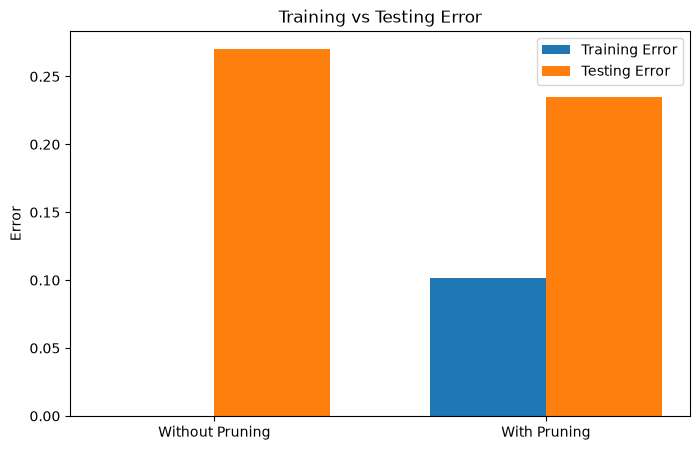

In [ ]:
# ==========================================
# 13. Error Comparison
# ==========================================

labels = ["Without Pruning", "With Pruning"]

train_errors = [
    train_error_no,
    train_error_pruned
]

test_errors = [
    test_error_no,
    test_error_pruned
]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2,
    train_errors,
    width,
    label="Training Error"
)

plt.bar(
    x + width/2,
    test_errors,
    width,
    label="Testing Error"
)

plt.xticks(x, labels)
plt.ylabel("Error")
plt.title("Training vs Testing Error")
plt.legend()

plt.show()

## Visualize both trees

Decision Tree with no Pruning


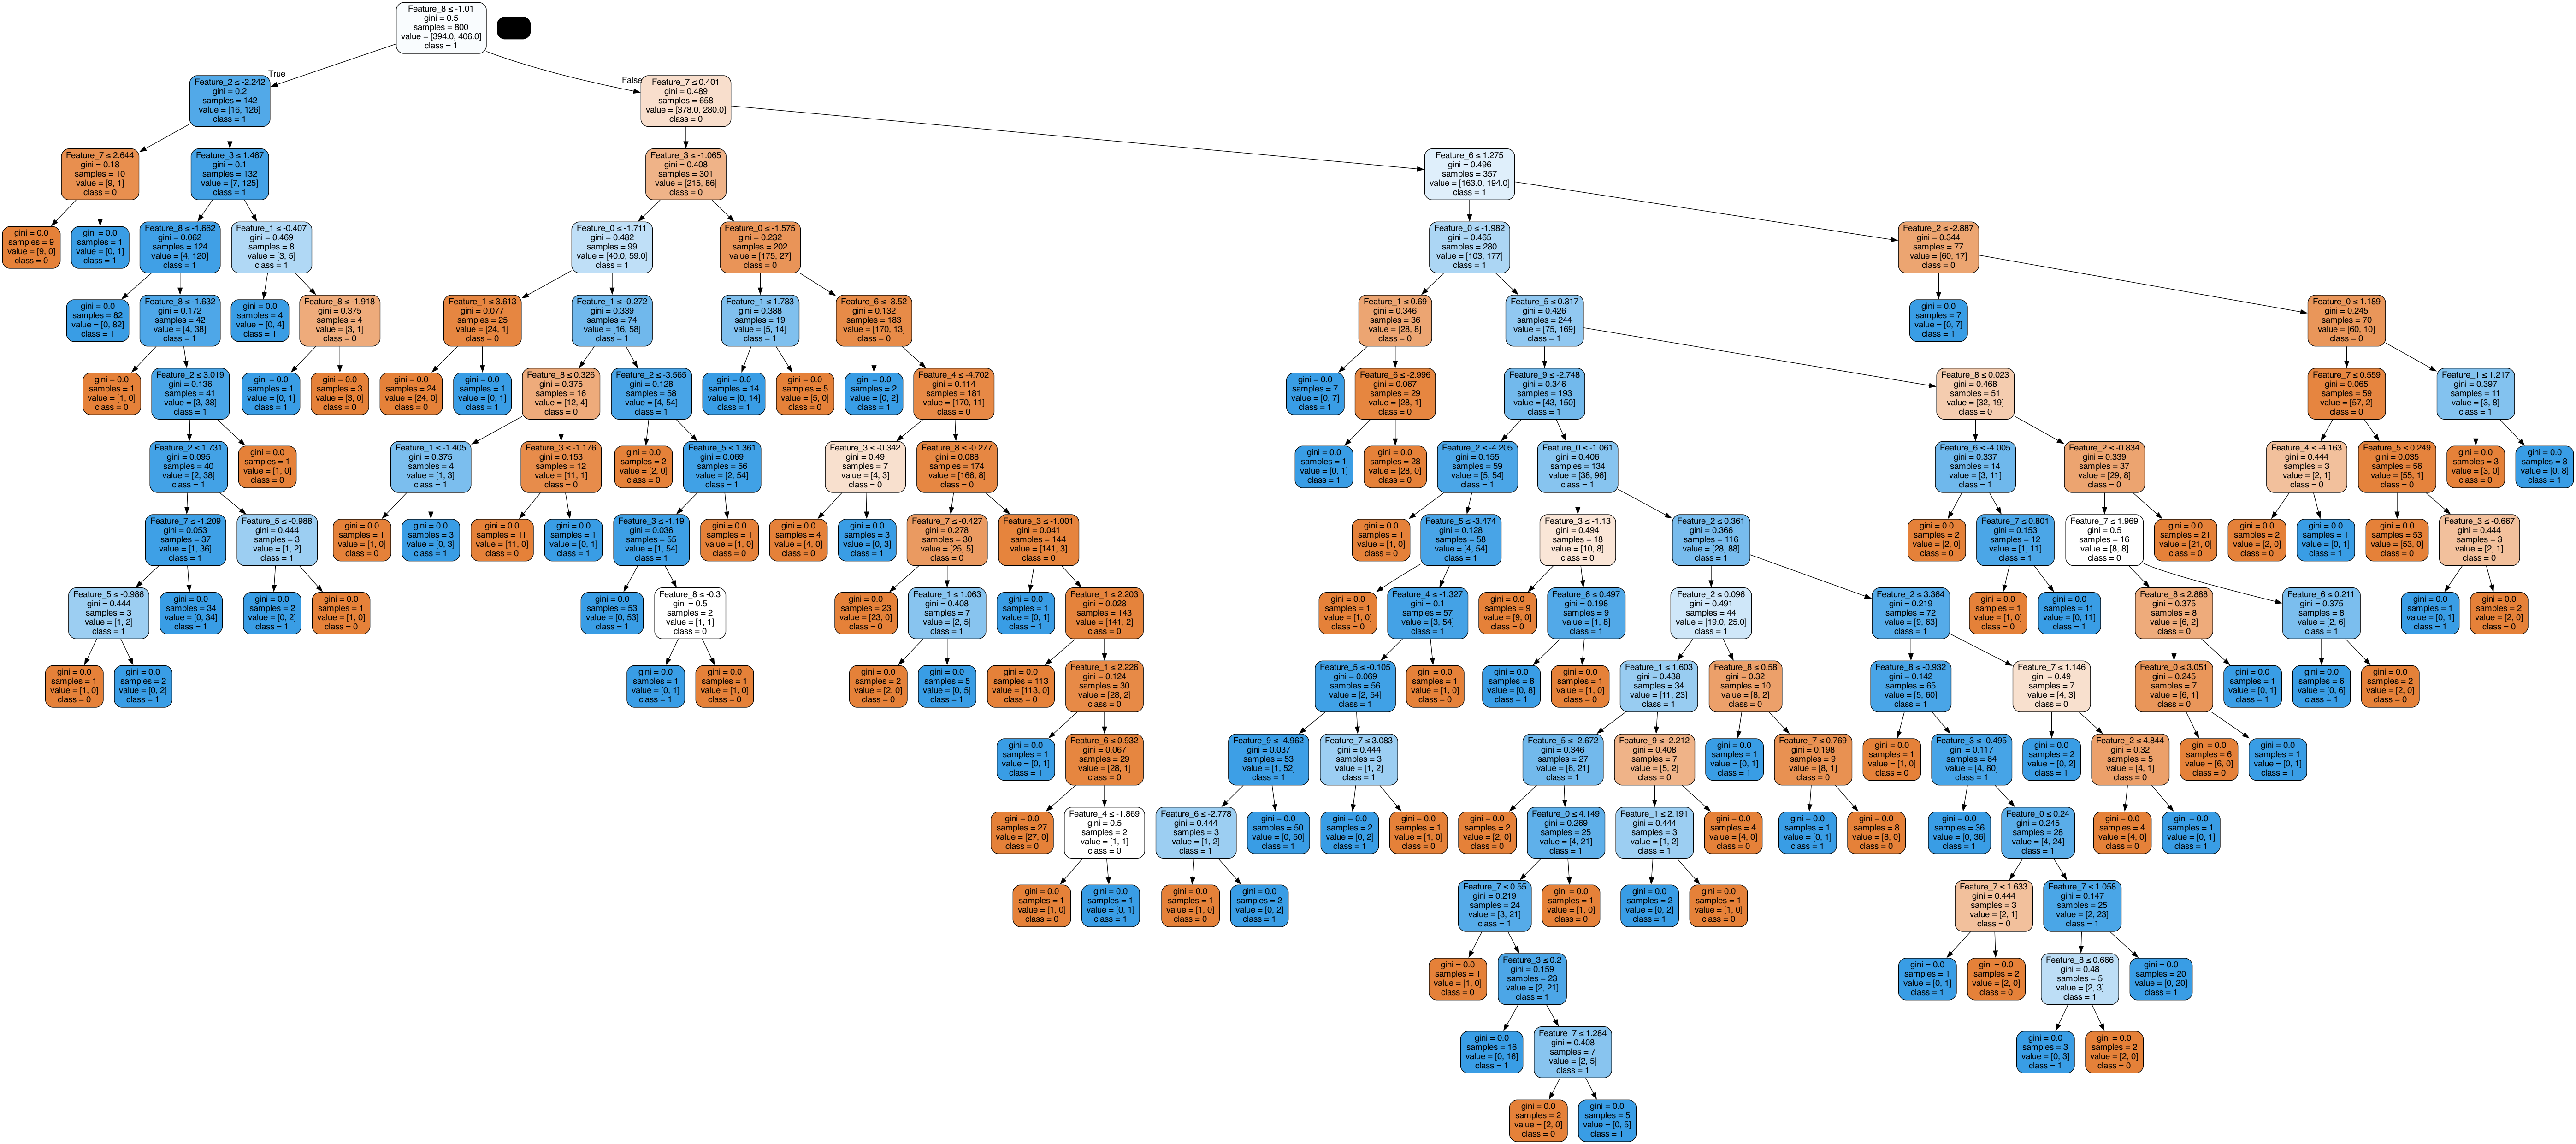

In [ ]:
# ==========================================
# 12. Visualize Trees
# ==========================================

from io import StringIO
from IPython.display import Image, display
import pydotplus
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.tree import export_graphviz
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


def get_dt_graph(dt_classifier, feature_names, class_names=None):
    """Create a graph object for a trained Decision Tree."""

    if class_names is None:
        class_names = [str(cls) for cls in dt_classifier.classes_]

    dot_data = StringIO()

    export_graphviz(
        dt_classifier,
        out_file=dot_data,
        filled=True,
        rounded=True,
        special_characters=True,
        feature_names=feature_names,
        class_names=class_names
    )

    graph = pydotplus.graph_from_dot_data(dot_data.getvalue())

    return graph

def visualize_tree(dt_classifier, feature_names, class_names=None):
    """Display a trained Decision Tree."""

    graph = get_dt_graph(
        dt_classifier,
        feature_names=feature_names,
        class_names=class_names
    )

    display(Image(graph.create_png()))

feature_names = [f"Feature_{i}" for i in range(X.shape[1])]

print("Decision Tree with no Pruning")
visualize_tree(tree_no_pruning,feature_names)

Decision Tree with Pruning


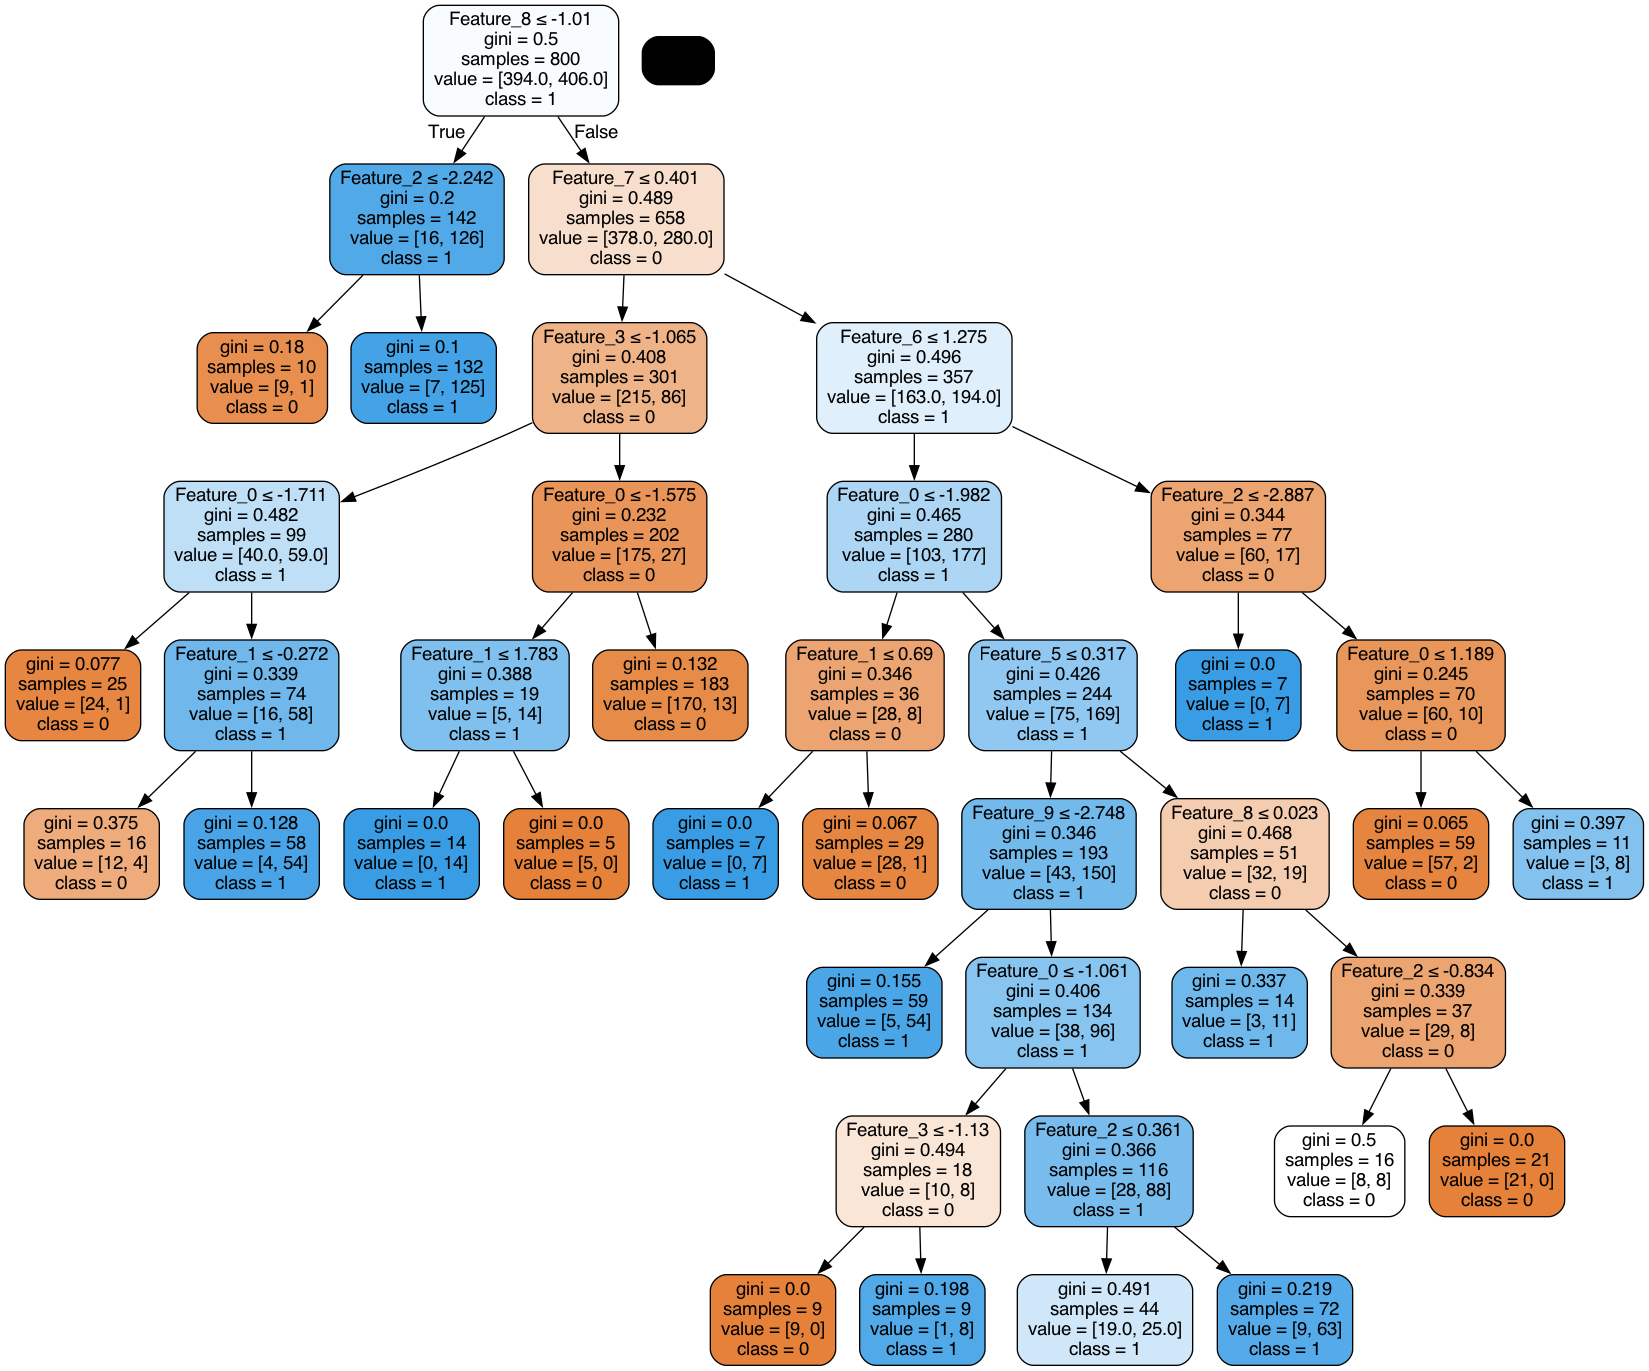

In [ ]:
print("Decision Tree with Pruning")
visualize_tree(tree_pruned,feature_names)

# **PART 4 — Hyperparameters & Tuning**

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

params = {
    "max_depth":[3,5,7,10],
    "min_samples_leaf":[5,10,20],
    "ccp_alpha":[0.0,0.001,0.01]
}

grid = GridSearchCV(
    DecisionTreeClassifier(),
    params,
    cv=5
)

grid.fit(X_train,y_train)

print(grid.best_params_)

{'ccp_alpha': 0.0, 'max_depth': 10, 'min_samples_leaf': 5}


# **PART 5 — Customer Churn Case Study**

# 📊 Business Problem

### Predict:

**Will the customer leave the company?**

---

## 💡 Why Is This Important?

### Customer Acquisition
- **Expensive**

### Customer Retention
- **Cheaper**

---

## 📋 Dataset Features

| Feature | Meaning |
|---|---|
| **Tenure** | Customer age |
| **Monthly Charges** | Monthly spend |
| **Contract Type** | Plan type |
| **Payment Method** | Payment mode |
| **Support Tickets** | Complaint frequency |

In [ ]:
# DATA CLEANING

import pandas as pd
from sklearn.datasets import make_classification

# Create synthetic churn dataset
X, y = make_classification(
    n_samples=1000,
    n_features=8,
    n_informative=6,
    n_redundant=2,
    random_state=42
)

# Create DataFrame
df = pd.DataFrame(
    X,
    columns=[
        "Tenure",
        "MonthlyCharges",
        "TotalCharges",
        "SupportCalls",
        "UsageHours",
        "ContractLength",
        "Complaints",
        "Satisfaction"
    ]
)

df["Churn"] = y

# Features and Target
X = df.drop("Churn", axis=1)
y = df["Churn"]

print(df.head())
print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

     Tenure  MonthlyCharges  TotalCharges  SupportCalls  UsageHours  \
0 -1.732538        5.260112     -2.952194     -4.603768    2.235848   
1  2.072914        2.240572     -1.385104     -2.514962   -0.984756   
2 -0.263106        1.527781     -1.872414     -0.028009    1.612809   
3 -0.164349       -0.550131     -0.019503     -0.765000    2.273523   
4 -1.419423        1.015324     -0.864441     -0.009297    0.385404   

   ContractLength  Complaints  Satisfaction  Churn  
0        1.928893   -0.101845      3.193487      0  
1        1.436260   -1.255271      2.089872      0  
2        3.264194   -1.296421      1.537870      0  
3        2.084217   -0.321931      0.426253      0  
4        0.449093   -0.029007     -1.902917      1  

X Shape: (1000, 8)
y Shape: (1000,)


In [ ]:
X.head()

,Tenure,MonthlyCharges,TotalCharges,SupportCalls,UsageHours,ContractLength,Complaints,Satisfaction
0,-1.732538,5.260112,-2.952194,-4.603768,2.235848,1.928893,-0.101845,3.193487
1,2.072914,2.240572,-1.385104,-2.514962,-0.984756,1.436260,-1.255271,2.089872
2,-0.263106,1.527781,-1.872414,-0.028009,1.612809,3.264194,-1.296421,1.537870
3,-0.164349,-0.550131,-0.019503,-0.765000,2.273523,2.084217,-0.321931,0.426253
4,-1.419423,1.015324,-0.864441,-0.009297,0.385404,0.449093,-0.029007,-1.902917


**Train Tree**

In [ ]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    ccp_alpha=0.002
)

model.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",0.002
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If N

**Evaluation**

In [ ]:
from sklearn.metrics import roc_auc_score

pred_prob = model.predict_proba(X_test)[:,1]

roc_auc_score(
    y_test,
    pred_prob
)

0.9118147258903562

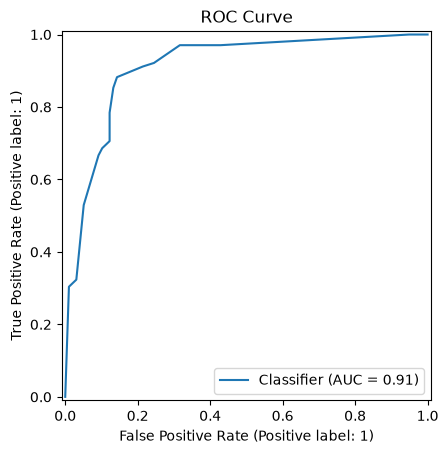

In [ ]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Predicted probability for the positive class
pred_prob = model.predict_proba(X_test)[:, 1]

# Plot ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    pred_prob
)

plt.title("ROC Curve")
plt.show()

# 🎯 Why ROC-AUC?

## ⚖️ Churn Datasets Are Often Imbalanced

When one class is much larger than the other:

- **Accuracy can be misleading**
- **ROC-AUC** gives a better view of how well the model separates the two classes.

---

## 💡 Business Insights

A Decision Tree can discover combinations of factors such as:

**Month-to-Month Contract**  
**AND**  
**High Charges**  
**AND**  
**Many Support Tickets**  
**↓**  
### 🔴 High Churn Probability

---

## 🎯 Action

**Target these customers with a retention campaign.**

# **PART 6 — Model Interpretation**

**Why Trees Are Popular**

- Unlike Neural Networks:

  - Trees are explainable.

**Global Interpretation**
- Feature Importance

In [ ]:
# import pandas as pd
# from sklearn.datasets import make_classification
# from sklearn.tree import DecisionTreeClassifier

# # Create synthetic dataset
# X, y = make_classification(
#     n_samples=1000,
#     n_features=8,
#     n_informative=6,
#     n_redundant=2,
#     random_state=42
# )

# # Convert to DataFrame so X.columns exists
# X = pd.DataFrame(
#     X,
#     columns=[
#         "Tenure",
#         "MonthlyCharges",
#         "TotalCharges",
#         "SupportCalls",
#         "UsageHours",
#         "ContractLength",
#         "Complaints",
#         "Satisfaction"
#     ]
# )

# # Train Decision Tree
# model = DecisionTreeClassifier(random_state=42)
# model.fit(X, y)

# Feature Importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

          Feature  Importance
1  MonthlyCharges    0.673124
7    Satisfaction    0.091410
0          Tenure    0.083524
5  ContractLength    0.065770
4      UsageHours    0.055833
6      Complaints    0.015885
2    TotalCharges    0.014453
3    SupportCalls    0.000000


**Tree Visualization**

[Text(0.5961538461538461, 0.9166666666666666, 'x[1] <= 1.209\ngini = 0.5\nsamples = 800\nvalue = [397, 403]'),
 Text(0.34615384615384615, 0.75, 'x[0] <= 0.149\ngini = 0.369\nsamples = 487\nvalue = [119, 368]'),
 Text(0.47115384615384615, 0.8333333333333333, 'True  '),
 Text(0.19230769230769232, 0.5833333333333334, 'x[7] <= 1.657\ngini = 0.499\nsamples = 127\nvalue = [61, 66]'),
 Text(0.15384615384615385, 0.4166666666666667, 'x[1] <= 0.224\ngini = 0.482\nsamples = 99\nvalue = [40.0, 59.0]'),
 Text(0.07692307692307693, 0.25, 'x[5] <= 1.094\ngini = 0.33\nsamples = 48\nvalue = [10, 38]'),
 Text(0.038461538461538464, 0.08333333333333333, 'gini = 0.071\nsamples = 27\nvalue = [1, 26]'),
 Text(0.11538461538461539, 0.08333333333333333, 'gini = 0.49\nsamples = 21\nvalue = [9, 12]'),
 Text(0.23076923076923078, 0.25, 'x[6] <= -0.52\ngini = 0.484\nsamples = 51\nvalue = [30, 21]'),
 Text(0.19230769230769232, 0.08333333333333333, 'gini = 0.346\nsamples = 27\nvalue = [21, 6]'),
 Text(0.269230769230769

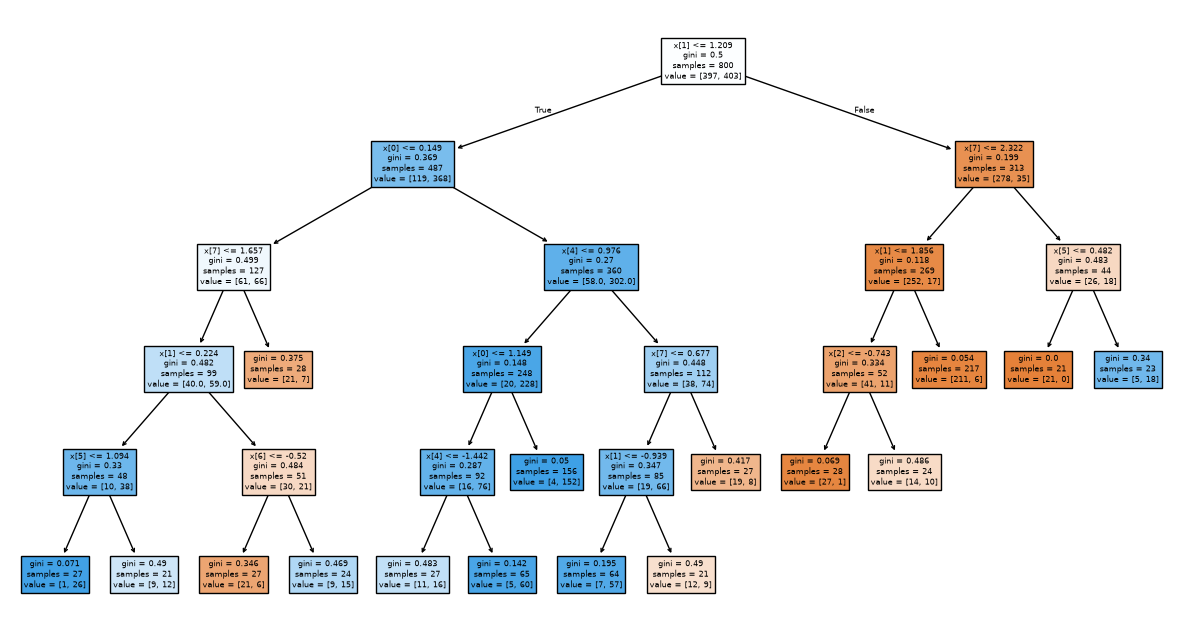

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(15,8))

plot_tree(
    model,
    filled=True
)

# 🔍 Local Interpretation

### Decision Path

For an individual customer, we can follow the path taken through the tree:

**Tenure < 12**

↓

**Monthly Charges > 80**  

↓  

**Support Tickets > 5**  
↓  
### → Churn

This shows **why the model predicted churn for that specific customer**.

---

# 📋 Rule Extraction

A Decision Tree naturally creates **IF-THEN rules**.

### Example

**IF** Tenure < 6  
**AND** Contract = Monthly  

**THEN** Churn = Yes

# **PART 7 — Advanced Techniques & Summary**

# ✂️ Reduced Error Pruning

### How It Works

1. **Remove a branch** from the decision tree.
2. Check the model's **validation accuracy**.
3. If the performance **does not decrease significantly**, keep the branch removed.
4. Otherwise, keep the original branch.

### ✅ Advantage

- **Simple**
- **Easy to explain**

---

# ✂️ Minimal Cost-Complexity Pruning

### How It Works

The tree is pruned by balancing:

- **Model error**
- **Tree complexity**

It is controlled by:ccp_alpha

# 🌲 Soft Pruning via Ensembles

Instead of pruning a single tree, we can reduce overfitting by **using many trees together**.

Each tree may learn different patterns, and combining them gives a more robust model.

### Examples

* **Random Forest**
* **Gradient Boosting**
* **XGBoost**
* **LightGBM**

# 📈 Monotonic Constraints

### What Are They?

Monotonic constraints are **domain-driven rules** that force the model to follow known business logic.

### Example

**Income ↑**  
↓  
**Loan Approval Probability ↑**

The model is forced to maintain this relationship.

---

# 🔄 Surrogate Splits

### Problem

A decision tree may encounter **missing values** for the feature used in a split.

### Solution

Use a **backup split**, called a surrogate split.

### Example

**Primary Split:**

Income

**Income Missing?**  
↓  
Use:

Salary

The backup feature helps make the decision when the primary feature is unavailable.

---

# 📋 Master Summary Table

| Concept | Purpose |
|---|---|
| **Pre-Pruning** | Stop tree growth early |
| **Post-Pruning** | Remove branches later |
| **`max_depth`** | Control tree depth |
| **`min_samples_leaf`** | Stabilize leaves |
| **`ccp_alpha`** | Cost-complexity pruning |
| **ROC-AUC** | Churn evaluation |
| **Feature Importance** | Model interpretation |
| **Surrogate Splits** | Handle missing values |

# ⚖️ Impact of `class_weight` on Gini Calculation

Suppose we have an imbalanced dataset:

- **Class 0 = 90**
- **Class 1 = 10**

Consider a split:

| Node | Class 0 | Class 1 | Total |
|---|---:|---:|---:|
| Parent | 90 | 10 | 100 |
| Left | 75 | 5 | 80 |
| Right | 15 | 5 | 20 |

---

## 1. Without `class_weight`

### Parent Gini

$$
Gini = 1-\left(\frac{90}{100}\right)^2-\left(\frac{10}{100}\right)^2
=0.18
$$

### Weighted Gini after split

$$
Gini_{split}
=
\frac{80}{100}(0.1172)
+
\frac{20}{100}(0.375)
$$

$$
\boxed{Gini_{split}=0.1688}
$$

### Gini Reduction

$$
0.18-0.1688=\boxed{0.0112}
$$

---

## 2. With `class_weight={0:1, 1:5}`

Class 1 gets **5× more importance**.

### Weighted Parent Counts

$$
Class\ 0 = 90\times1=90
$$

$$
Class\ 1 = 10\times5=50
$$

So:

$$
Total=140
$$

The minority class now has much more influence on the impurity calculation.

### Weighted Gini Reduction

Using the weighted child counts:

$$
Gini_{parent}\approx0.459
$$

$$
Gini_{split}\approx0.4018
$$

Therefore:

$$
0.459-0.4018
=
\boxed{0.0572}
$$

---

## 🔥 What Changed?

| | Without Weight | `class_weight={0:1,1:5}` |
|---|---:|---:|
| Gini Reduction | **0.0112** | **0.0572** |
| Minority Class Influence | Low | High |

> **Without `class_weight`, the majority class dominates the impurity calculation.**

> **With `class_weight`, the minority class gets higher importance, so splits that better separate the minority class become more valuable.**